# CmdStanPy parameter-recovery validation for DLMMC

This notebook generates short synthetic time series with the DLM simulators in `utils/dlm.py`, fits them through the public `dlmmc.fit()` API, and compares known inputs with posterior intervals. It covers vanilla AR1, vanilla AR2, no-regressor AR1, and dynamic-regressor AR1.

Each test uses 120 monthly observations, four chains, 250 warmup iterations, and 500 sampling iterations per chain. These are parameter-recovery demonstrations, not exhaustive convergence certification. Install the project and run `python compile_stan_models.py` only if you want to precompile all models before starting.

In [ ]:
# Imports for simulation, package fitting, xarray, and diagnostic summaries
import numpy as np
import pandas as pd
import xarray as xr
import arviz as az
import matplotlib.pyplot as plt
import dlmmc
from utils.dlm import (
    simulate_x_y_dlm_vanilla_ar1,
    simulate_x_y_dlm_vanilla_ar2,
    simulate_x_y_dlm_noregs_ar1,
    simulate_x_y_dlm_dynregs_ar1,
)
%matplotlib inline

## Prepare a small xarray time axis and regressors

The simulators provide synthetic observations; the example NetCDF is only used for its first 120 monthly time coordinates. Each regressor file is loaded using only its time column and the selected value column, decoded from IDL Julian days, and interpolated with xarray. No ozone or unrelated NetCDF variables are read.

In [ ]:
# Load only the first 120 time coordinates and the regressor columns used here
n_time = 120
with xr.open_dataset('data/BASIC_V1_2017_lotus_seascyc_gcsw2017_fac2.nc') as source:
    idl_julian = source['time'].isel(time=slice(0, n_time)).to_numpy()
time = xr.DataArray(
    pd.to_datetime(idl_julian, unit='D', origin='julian'),
    dims=('time',),
    name='time',
)

latitude = 8
regressor_names = ['ENSO', 'SOLAR', 'QBO30', 'QBO50', 'SAOD']
regressor_files = [
    ('regressors/ENSO_MEI_1950_201802.txt', 1),
    ('regressors/Flux_F30_monthly_195111_201803_absolute.txt', 1),
    ('regressors/multi_qbo30_1953_2018.txt', 1),
    ('regressors/multi_qbo50_1953_2018.txt', 1),
    ('regressors/sad_1979_2017_10deg_60S_60N.txt', latitude + 1),
]

def interpolate_regressor(path, column):
    values = np.loadtxt(path, usecols=(0, column))
    regressor_time = pd.to_datetime(values[:, 0], unit='D', origin='julian')
    regressor = xr.DataArray(
        values[:, 1], dims=('time',), coords={'time': regressor_time}
    )
    return regressor.interp(time=time).to_numpy()

regressors = np.column_stack([
    interpolate_regressor(path, column)
    for path, column in regressor_files
])
n_regressors = regressors.shape[1]
regressors_da = xr.DataArray(
    regressors,
    dims=('time', 'regressor'),
    coords={'time': time, 'regressor': regressor_names},
)
chains = 4
warmup = 250
sampling = 500


def run_parameter_recovery(model_name, seed=0):
    np.random.seed(seed)
    sigma_trend = 5e-5
    sigma_seas = 1e-2
    sigma_AR = 0.1
    rhoAR1 = 0.3
    rhoAR2 = 0.1
    sigma_reg = np.full(n_regressors, 1e-2)
    observation_sd = np.full(n_time + 1, 0.1)
    S = 10.0

    has_regressors = model_name != 'dlm_noregs_ar1'
    is_dynamic = model_name == 'dlm_dynregs_ar1'
    is_ar2 = model_name == 'dlm_vanilla_ar2'
    nx = 7 if not has_regressors else n_regressors + (8 if is_ar2 else 7)
    x0 = np.concatenate([np.array([1.0, 1e-3]), np.ones(nx - 2)])
    variance = observation_sd**2

    if model_name == 'dlm_vanilla_ar1':
        state, generated = simulate_x_y_dlm_vanilla_ar1(
            x0, sigma_trend, sigma_seas, sigma_AR, rhoAR1,
            regressors, S, variance, n_time, nx,
        )
    elif is_ar2:
        state, generated = simulate_x_y_dlm_vanilla_ar2(
            x0, sigma_trend, sigma_seas, sigma_AR, rhoAR1, rhoAR2,
            regressors, S, variance, n_time, nx,
        )
    elif model_name == 'dlm_noregs_ar1':
        state, generated = simulate_x_y_dlm_noregs_ar1(
            x0, sigma_trend, sigma_seas, sigma_AR, rhoAR1,
            S, variance, n_time, nx,
        )
    elif is_dynamic:
        state, generated = simulate_x_y_dlm_dynregs_ar1(
            x0, sigma_trend, sigma_seas, sigma_AR, rhoAR1, sigma_reg,
            regressors, S, variance, n_time, nx,
        )
    else:
        raise ValueError(f'Unsupported validation model: {model_name}')

    series = xr.DataArray(generated[1:], dims=('time',), coords={'time': time})
    uncertainty = xr.DataArray(observation_sd[1:], dims=('time',), coords={'time': time})
    data_range = float(np.ptp(generated[1:]))
    if not np.isfinite(data_range) or data_range <= 0:
        raise ValueError(f'Invalid simulated data range for {model_name}: {data_range}')

    priors = {
        'S': S / data_range if is_dynamic else S,
        'sigma_trend_prior': 2.5e-4 / data_range,
        'sigma_seas_prior': 5e-2 / data_range,
        'sigma_AR_prior': 0.5 / data_range,
    }
    initial_values = {
        'sigma_trend': sigma_trend / data_range,
        'sigma_seas': sigma_seas / data_range,
        'sigma_AR': sigma_AR / data_range,
        'rhoAR1': rhoAR1,
    }
    if is_ar2:
        initial_values['rhoAR2'] = rhoAR2
    if is_dynamic:
        priors['sigma_reg_prior'] = np.full(n_regressors, 5e-2 / data_range).tolist()
        initial_values['sigma_reg'] = (sigma_reg / data_range).tolist()

    true_values = {
        'sigma_trend': sigma_trend,
        'sigma_seas': sigma_seas,
        'sigma_AR': sigma_AR,
        'rhoAR1': rhoAR1,
    }
    if is_ar2:
        true_values['rhoAR2'] = rhoAR2
    if has_regressors and not is_dynamic:
        true_values['beta'] = state[6:6 + n_regressors, 1]
    if is_dynamic:
        true_values['sigma_reg'] = sigma_reg

    model_name_api = model_name.removeprefix('dlm_')
    fit = dlmmc.fit(
        data=series,
        uncertainty=uncertainty,
        regressors=regressors_da if has_regressors else None,
        model=model_name_api,
        priors=priors,
        chains=chains,
        warmup=warmup,
        samples=sampling,
        seed=seed,
        inits=[initial_values.copy() for _ in range(chains)],
        show_progress=False,
    )

    diagnostic_parameters = list(true_values)
    display(az.summary(
        fit[diagnostic_parameters],
        sample_dims=['chain', 'draw'],
        kind='all',
        round_to=3,
    ))

    recovery_rows = []
    for name, truth in true_values.items():
        values = fit[name].to_numpy()
        if name.startswith('sigma_'):
            values = values * data_range
        flattened = values.reshape((-1,) + values.shape[2:])
        lower, median, upper = np.quantile(flattened, [0.05, 0.5, 0.95], axis=0)
        truth = np.asarray(truth)
        indices = list(np.ndindex(truth.shape)) if truth.shape else [()]
        for index in indices:
            true_value = truth[index] if index else truth.item()
            lo = lower[index] if index else lower.item()
            med = median[index] if index else median.item()
            hi = upper[index] if index else upper.item()
            label = f'{name}[{index[0] + 1}]' if index else name
            recovery_rows.append({
                'parameter': label,
                'true value': true_value,
                'posterior median': med,
                '90% interval': f'[{lo:.4g}, {hi:.4g}]',
                'covered': bool(lo <= true_value <= hi),
            })
    recovery = pd.DataFrame(recovery_rows)
    display(recovery)

    trend_draws = fit['trend'].transpose('chain', 'draw', 'time').to_numpy().reshape(-1, n_time)
    lower, median, upper = np.quantile(trend_draws, [0.05, 0.5, 0.95], axis=0)
    true_trend = state[0, 1:]
    coverage = np.mean((true_trend >= lower) & (true_trend <= upper))
    print(f'Trend 90% interval coverage across times: {coverage:.1%}')
    print(f'Divergent transitions: {fit.attrs.get("divergent_transitions", "unavailable")}')
    plt.plot(time, true_trend, color='black', label='simulated trend')
    plt.plot(time, median, color='tab:blue', label='posterior median')
    plt.fill_between(time, lower, upper, color='tab:blue', alpha=0.2, label='90% interval')
    plt.xlabel('Date')
    plt.ylabel('Trend')
    plt.gcf().autofmt_xdate()
    plt.legend()
    plt.show()
    return fit, recovery

# Test 1: vanilla AR1 with static regressors

Generate a synthetic series with known AR1 parameters, fit the CmdStanPy model, and compare the true hyperparameters and static regression coefficients with posterior 90% intervals. The trend plot also shows pointwise posterior coverage.

16:22:21 - cmdstanpy - INFO - CmdStan start processing
16:22:21 - cmdstanpy - INFO - Chain [1] start processing
16:22:21 - cmdstanpy - INFO - Chain [2] start processing
16:22:21 - cmdstanpy - INFO - Chain [3] start processing
16:22:21 - cmdstanpy - INFO - Chain [4] start processing
16:22:37 - cmdstanpy - INFO - Chain [1] done processing
16:22:37 - cmdstanpy - INFO - Chain [2] done processing
16:22:38 - cmdstanpy - INFO - Chain [4] done processing
16:22:39 - cmdstanpy - INFO - Chain [3] done processing
16:22:39 - cmdstanpy - WARNING - Non-fatal error during sampling:
Exception: normal_lpdf: Scale parameter is nan, but must be positive! (in 'dlm_vanilla_ar1_cmdstanpy.stan', line 178, column 8 to column 54)
Exception: normal_lpdf: Scale parameter is nan, but must be positive! (in 'dlm_vanilla_ar1_cmdstanpy.stan', line 178, column 8 to column 54)
Exception: normal_lpdf: Scale parameter is nan, but must be positive! (in 'dlm_vanilla_ar1_cmdstanpy.stan', line 178, column 8 to column 54)
Cons

,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
sigma_trend,0.000,0.000,0.000,0.000,757.902,558.770,1.005,0.000,0.000
sigma_seas,0.001,0.001,0.000,0.003,926.677,705.836,1.003,0.000,0.000
sigma_AR,0.016,0.003,0.011,0.020,895.383,630.947,1.002,0.000,0.000
rhoAR1,0.462,0.188,0.149,0.775,728.850,622.437,1.005,0.007,0.006
beta[0],0.935,0.169,0.666,1.192,1911.744,2040.163,1.001,0.004,0.003
beta[1],0.999,0.118,0.813,1.179,2344.846,1970.826,0.999,0.002,0.003
beta[2],1.146,0.080,1.007,1.267,1917.740,1814.046,1.001,0.002,0.002
beta[3],0.814,0.091,0.657,0.952,1781.213,1989.496,1.001,0.002,0.001
beta[4],0.935,0.109,0.772,1.099,2053.109,1966.531,1.000,0.002,0.002


,parameter,true value,posterior median,90% interval,covered
0,sigma_trend,0.00005,0.000174,"[1.151e-05, 0.0004829]",True
1,sigma_seas,0.01000,0.008658,"[0.001256, 0.02027]",True
2,sigma_AR,0.10000,0.108338,"[0.075, 0.1372]",True
3,rhoAR1,0.30000,0.461607,"[0.1383, 0.7805]",True
4,beta[1],1.00000,0.940349,"[0.655, 1.199]",True
5,beta[2],1.00000,1.004416,"[0.8074, 1.185]",True
6,beta[3],1.00000,1.150859,"[1.002, 1.27]",False
7,beta[4],1.00000,0.818119,"[0.6505, 0.9555]",False
8,beta[5],1.00000,0.936752,"[0.7673, 1.104]",True


Trend 90% interval coverage across times: 100.0%
Divergent transitions: 0


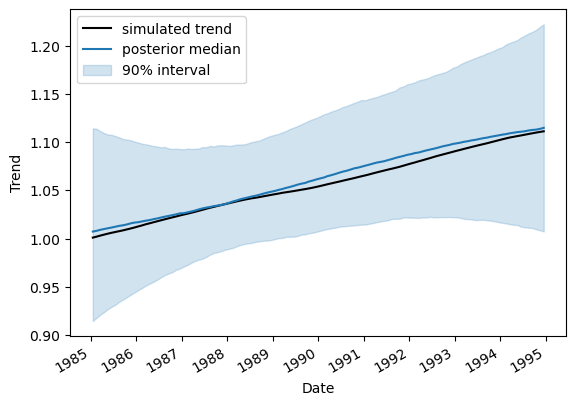

In [13]:
fit_vanilla_ar1, recovery_vanilla_ar1 = run_parameter_recovery('dlm_vanilla_ar1', seed=0)

# Test 2: vanilla AR2 with static regressors

Check recovery of the AR2 hyperparameters, including `rhoAR2`, along with the static regression coefficients.

16:23:04 - cmdstanpy - INFO - CmdStan start processing
16:23:04 - cmdstanpy - INFO - Chain [1] start processing
16:23:04 - cmdstanpy - INFO - Chain [2] start processing
16:23:04 - cmdstanpy - INFO - Chain [3] start processing
16:23:04 - cmdstanpy - INFO - Chain [4] start processing
16:23:21 - cmdstanpy - INFO - Chain [1] done processing
16:23:23 - cmdstanpy - INFO - Chain [3] done processing
16:23:26 - cmdstanpy - INFO - Chain [4] done processing
16:23:27 - cmdstanpy - INFO - Chain [2] done processing
16:23:27 - cmdstanpy - WARNING - Non-fatal error during sampling:
Exception: normal_lpdf: Scale parameter is nan, but must be positive! (in 'dlm_vanilla_ar2_cmdstanpy.stan', line 186, column 8 to column 54)
	Exception: normal_lpdf: Scale parameter is nan, but must be positive! (in 'dlm_vanilla_ar2_cmdstanpy.stan', line 186, column 8 to column 54)
	Exception: normal_lpdf: Scale parameter is nan, but must be positive! (in 'dlm_vanilla_ar2_cmdstanpy.stan', line 186, column 8 to column 54)
	E

,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
sigma_trend,0.000,0.000,0.000,0.000,278.782,134.640,1.021,0.000,0.000
sigma_seas,0.001,0.001,0.000,0.002,295.392,295.702,1.017,0.000,0.000
sigma_AR,0.008,0.003,0.003,0.012,126.024,127.443,1.021,0.000,0.000
rhoAR1,0.217,0.138,0.020,0.453,231.850,268.330,1.007,0.009,0.003
rhoAR2,0.518,0.231,0.128,0.865,143.830,163.221,1.024,0.018,0.009
beta[0],1.054,0.129,0.857,1.260,1309.590,1012.130,1.001,0.004,0.002
beta[1],0.935,0.117,0.776,1.138,1507.857,1365.823,1.003,0.003,0.003
beta[2],1.084,0.052,1.003,1.166,1996.238,1836.223,1.000,0.001,0.001
beta[3],0.969,0.062,0.870,1.070,1766.796,1399.763,1.002,0.001,0.001
beta[4],1.161,0.086,1.029,1.302,1833.597,1799.714,1.001,0.002,0.002


,parameter,true value,posterior median,90% interval,covered
0,sigma_trend,0.00005,0.000163,"[1.672e-05, 0.0004918]",True
1,sigma_seas,0.01000,0.008366,"[0.003224, 0.01509]",True
2,sigma_AR,0.10000,0.050449,"[0.02099, 0.08501]",False
3,rhoAR1,0.30000,0.206972,"[0.0185, 0.4572]",True
4,rhoAR2,0.10000,0.532281,"[0.1234, 0.8686]",False
5,beta[1],1.00000,1.050117,"[0.8497, 1.263]",True
6,beta[2],1.00000,0.922639,"[0.7718, 1.147]",True
7,beta[3],1.00000,1.082980,"[1.001, 1.168]",False
8,beta[4],1.00000,0.968234,"[0.8644, 1.072]",True
9,beta[5],1.00000,1.160040,"[1.025, 1.305]",False


Trend 90% interval coverage across times: 100.0%
Divergent transitions: 1364


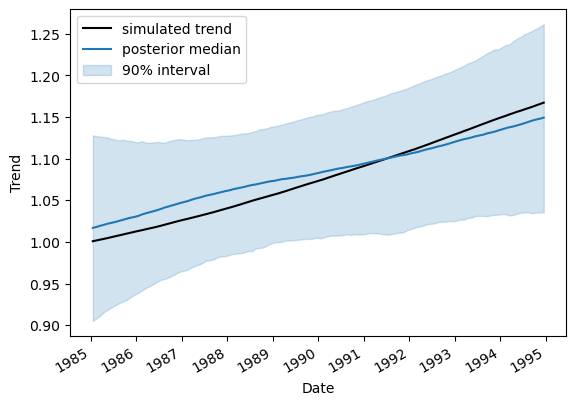

In [14]:
fit_vanilla_ar2, recovery_vanilla_ar2 = run_parameter_recovery('dlm_vanilla_ar2', seed=1)

# Test 3: no-regressor AR1

Generate and fit a no-regressor AR1 series. This case omits `nreg`, `regressors`, and regression coefficients from the model input and recovery table.

16:24:24 - cmdstanpy - INFO - CmdStan start processing
16:24:24 - cmdstanpy - INFO - Chain [1] start processing
16:24:24 - cmdstanpy - INFO - Chain [3] start processing
16:24:24 - cmdstanpy - INFO - Chain [2] start processing
16:24:24 - cmdstanpy - INFO - Chain [4] start processing
16:24:30 - cmdstanpy - INFO - Chain [4] done processing
16:24:30 - cmdstanpy - INFO - Chain [3] done processing
16:24:30 - cmdstanpy - INFO - Chain [2] done processing
16:24:31 - cmdstanpy - INFO - Chain [1] done processing
16:24:31 - cmdstanpy - WARNING - Non-fatal error during sampling:
Exception: normal_lpdf: Scale parameter is nan, but must be positive! (in 'dlm_noregs_ar1_cmdstanpy.stan', line 163, column 8 to column 54)
Exception: normal_lpdf: Scale parameter is nan, but must be positive! (in 'dlm_noregs_ar1_cmdstanpy.stan', line 163, column 8 to column 54)
Exception: normal_lpdf: Scale parameter is nan, but must be positive! (in 'dlm_noregs_ar1_cmdstanpy.stan', line 163, column 8 to column 54)
	Except

,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
sigma_trend,0.000,0.000,0.000,0.000,715.707,483.996,1.003,0.000,0.000
sigma_seas,0.001,0.000,0.000,0.001,1031.446,641.726,1.003,0.000,0.000
sigma_AR,0.016,0.003,0.011,0.021,1111.309,937.409,1.004,0.000,0.000
rhoAR1,0.476,0.189,0.159,0.777,940.536,997.758,1.006,0.006,0.004


,parameter,true value,posterior median,90% interval,covered
0,sigma_trend,0.00005,0.000147,"[1.278e-05, 0.0004263]",True
1,sigma_seas,0.01000,0.002772,"[0.0002569, 0.008159]",False
2,sigma_AR,0.10000,0.085353,"[0.05737, 0.1127]",True
3,rhoAR1,0.30000,0.483342,"[0.152, 0.7837]",True


Trend 90% interval coverage across times: 100.0%
Divergent transitions: 0


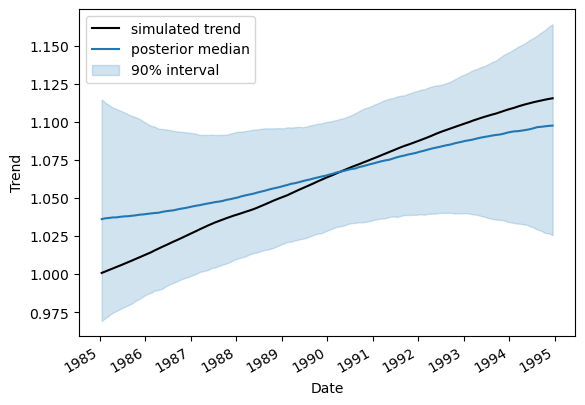

In [15]:
fit_noregs_ar1, recovery_noregs_ar1 = run_parameter_recovery('dlm_noregs_ar1', seed=2)

# Test 4: dynamic-regressor AR1

Check recovery of the AR1 hyperparameters and `sigma_reg` values for time-varying regression coefficients. The coefficient paths are not reduced to a single static `beta` vector.

16:24:43 - cmdstanpy - INFO - CmdStan start processing
16:24:43 - cmdstanpy - INFO - Chain [1] start processing
16:24:43 - cmdstanpy - INFO - Chain [2] start processing
16:24:43 - cmdstanpy - INFO - Chain [3] start processing
16:24:43 - cmdstanpy - INFO - Chain [4] start processing
16:25:04 - cmdstanpy - INFO - Chain [1] done processing
16:25:04 - cmdstanpy - INFO - Chain [3] done processing
16:25:04 - cmdstanpy - INFO - Chain [2] done processing
16:25:06 - cmdstanpy - INFO - Chain [4] done processing
16:25:06 - cmdstanpy - WARNING - Non-fatal error during sampling:
Exception: normal_lpdf: Scale parameter is nan, but must be positive! (in 'dlm_dynregs_ar1_cmdstanpy.stan', line 183, column 8 to column 54)
Exception: normal_lpdf: Scale parameter is nan, but must be positive! (in 'dlm_dynregs_ar1_cmdstanpy.stan', line 183, column 8 to column 54)
Consider re-running with show_console=True if the above output is unclear!


,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
sigma_trend,0.000,0.000,0.000,0.000,1156.893,703.834,1.003,0.000,0.000
sigma_seas,0.002,0.001,0.000,0.004,481.631,187.760,1.016,0.000,0.000
sigma_AR,0.012,0.004,0.005,0.017,280.688,154.269,1.027,0.000,0.000
rhoAR1,0.581,0.196,0.211,0.857,1267.456,855.098,1.002,0.006,0.006
sigma_reg[0],0.004,0.004,0.000,0.011,1017.812,659.700,1.002,0.000,0.000
sigma_reg[1],0.005,0.004,0.000,0.012,1523.980,871.200,1.000,0.000,0.000
sigma_reg[2],0.003,0.003,0.000,0.009,1374.661,628.407,1.001,0.000,0.000
sigma_reg[3],0.003,0.003,0.000,0.008,1029.657,699.883,1.004,0.000,0.000
sigma_reg[4],0.005,0.004,0.000,0.012,955.423,822.065,1.000,0.000,0.000


,parameter,true value,posterior median,90% interval,covered
0,sigma_trend,0.00005,0.000167,"[1.294e-05, 0.000469]",True
1,sigma_seas,0.01000,0.013973,"[0.003177, 0.0289]",True
2,sigma_AR,0.10000,0.086166,"[0.0306, 0.1207]",True
3,rhoAR1,0.30000,0.604283,"[0.1994, 0.8636]",True
4,sigma_reg[1],0.01000,0.024855,"[0.00235, 0.08196]",True
5,sigma_reg[2],0.01000,0.029288,"[0.002538, 0.0862]",True
6,sigma_reg[3],0.01000,0.018279,"[0.001665, 0.06593]",True
7,sigma_reg[4],0.01000,0.019176,"[0.001856, 0.06318]",True
8,sigma_reg[5],0.01000,0.028070,"[0.0025, 0.08929]",True


Trend 90% interval coverage across times: 100.0%
Divergent transitions: 0


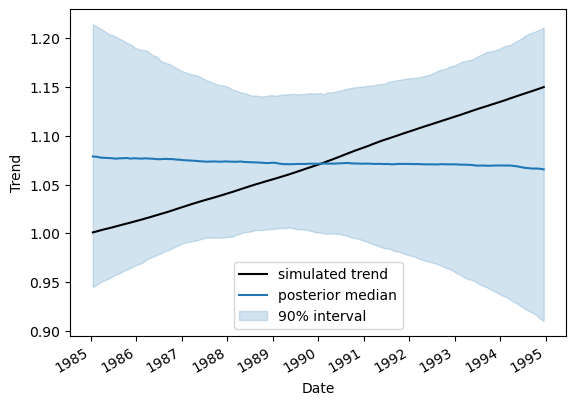

In [16]:
fit_dynregs_ar1, recovery_dynregs_ar1 = run_parameter_recovery('dlm_dynregs_ar1', seed=3)